In [28]:
import numpy as np
import matplotlib as mpl

In [29]:
from pdadic import NAryTree
from pdadic import QTreeMap

from pdadic import  QTreeDiagonalOperator
from pdadic.examples import PowerKernelOperator
from pdadic.examples import GaussianKernelOperator
from pdadic.examples import TruncatedGaussianKernelOperator

from pdadic.ploting import PlotParameters
from pdadic.ploting import EvolutionDiscussion
from pdadic.ploting import show

In [30]:
mpl.rcParams["text.usetex"] = True
mpl.rcParams["font.family"] = "serif"
mpl.rcParams["font.size"] = "16"
mpl.rcParams["text.latex.preamble"] = r"""
\usepackage{amsmath}
\usepackage{amssymb}
\usepackage{bm}
\usepackage{lmodern}  % Optional: for better scaling of Computer Modern
"""

In [31]:
HEIGHT = 6
DEGREE = 3

qtree = NAryTree(DEGREE, HEIGHT)
func = lambda x: np.exp(-2**4 * (x - 0.5)**2)
# func = lambda x: 1 - abs(x-0.5)/5
qfunc = QTreeMap.from_function(qtree, func)
# qdecomp = qfunc.to_decomposition()

In [32]:
PARAMS = PlotParameters(
    columns         = 1,
    subplot_height  = 4.5,
    subplot_width   = 5.5,
    margin_top      = .9,
)


def discuss_operators(operators, labels, dilations):
    for op, label ,tau in zip(operators, labels, dilations):
        discussion = EvolutionDiscussion(op, qfunc,
            dilation=tau,
            params=PARAMS,
        ).single(label + fr", $\tau={tau}$")
        print("The eigenvalues are:")
        print(op.eigenvalues)
        show(discussion)
        discussion.savefig(
            f"../images/{str(op)}.png", dpi=400
        )

self.T=np.float64(8.368)
The eigenvalues are:
[1.         0.77777778 0.75308642 0.75034294 0.7500381  0.75000423]


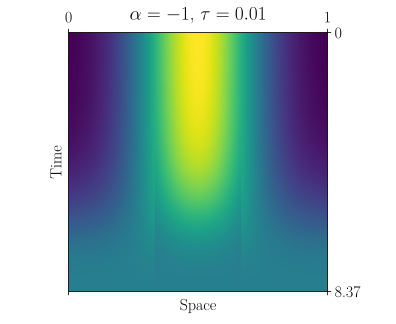

self.T=np.float64(6.696)
The eigenvalues are:
[1.         1.105358   1.15157765 1.17185381 1.18074878 1.18465093]


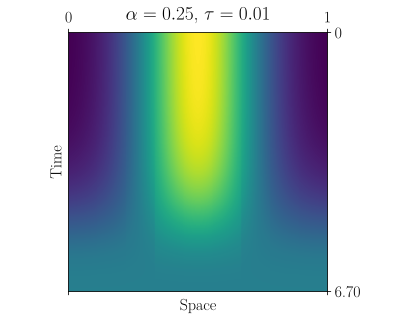

self.T=np.float64(6.473520000000001)
The eigenvalues are:
[1.         1.65574067 2.30431672 2.94580643 3.58028723 4.20783569]


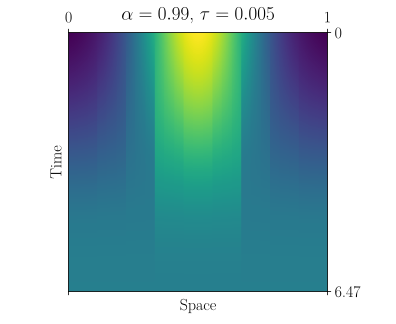

In [33]:
ALPHAS = [-1, 1/4, .99]
POWER_DILATIONS = [.01, .01, .005]
# POWER_DILATIONS = len(ALPHAS) * [0.01,]
power_kernel_operators = [
    PowerKernelOperator(qtree, alpha)
    for alpha in ALPHAS
]
power_kernel_labels = [
    fr"$\alpha={alpha}$"
    for alpha in ALPHAS
]

discuss_operators(
    operators   = power_kernel_operators,
    labels      = power_kernel_labels,
    dilations   = POWER_DILATIONS,
)

self.T=np.float64(27.328)
The eigenvalues are:
[0.24197072 0.28710823 0.2892309  0.28931169 0.28931469 0.2893148 ]


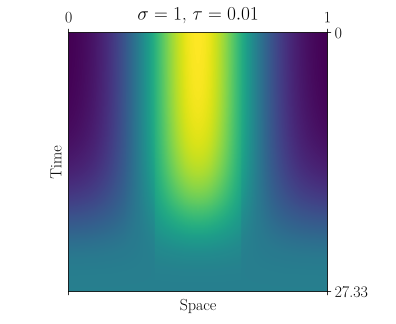

self.T=np.float64(1258.26048)
The eigenvalues are:
[0.00514093 0.24253002 0.30079105 0.30368196 0.3037927  0.30379682]


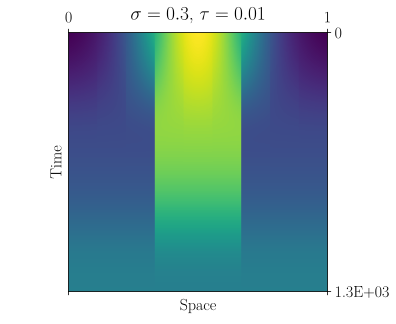

self.T=np.float64(870318.08)
The eigenvalues are:
[7.43359757e-06 1.65800187e-01 3.00475273e-01 3.09784111e-01
 3.10155897e-01 3.10169783e-01]


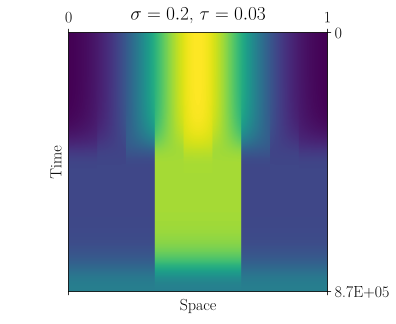

In [34]:
SIGMAS = [1, .3, .2,]
GAUSSIAN_DILATIONS = [.01, .01, .03]
# GAUSSIAN_DILATIONS = len(SIGMAS) * [0.01,]

gaussian_kernel_operators = [
    GaussianKernelOperator(qtree, sigma)
    for sigma in SIGMAS
]
gaussian_kernel_labels = [
    fr"$\sigma={sigma}$"
    for sigma in SIGMAS
]

discuss_operators(
    operators   = gaussian_kernel_operators,
    labels      = gaussian_kernel_labels,
    dilations   = GAUSSIAN_DILATIONS,
)

self.T=np.float64(6.472)
The eigenvalues are:
[ 1  2  4  8 16 32]


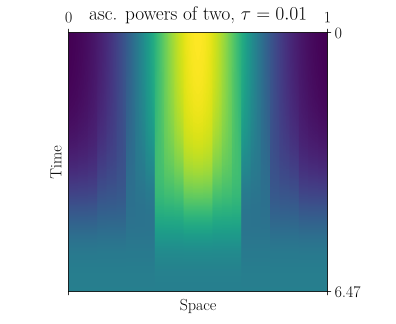

self.T=np.float64(6.472)
The eigenvalues are:
[ 1 17 25 29 31 32]


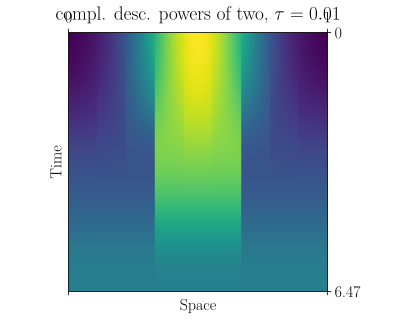

self.T=np.float64(2.469528)
The eigenvalues are:
[32 16  8  4  2  1]


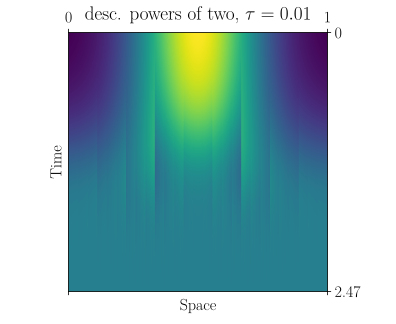

self.T=np.float64(2.244)
The eigenvalues are:
[32 31 29 25 17  1]


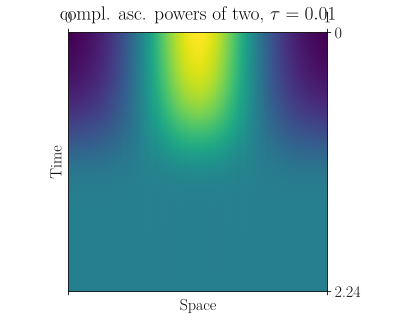

In [41]:
POWERS_OF_TWO=[2**i for i in range(HEIGHT)]
CPOWERS_OF_TWO=[1 + 2**(HEIGHT-1) - 2**i for i in range(HEIGHT)]

discuss_operators(
    operators   = [
        QTreeDiagonalOperator(qtree, POWERS_OF_TWO),
        QTreeDiagonalOperator(qtree, CPOWERS_OF_TWO[::-1]),
        QTreeDiagonalOperator(qtree, POWERS_OF_TWO[::-1]),
        QTreeDiagonalOperator(qtree, CPOWERS_OF_TWO),
    ],
    labels      = [
        "asc. powers of two",
        "compl. desc. powers of two",
        "desc. powers of two",
        "compl. asc. powers of two",
    ],
    dilations = [0.01, 0.01, 0.01, 0.01],
)